# Outlier Detection Lab
### CSCI 4047 - Module 09

An outlier is a point that looks like it came from a different process than the rest of the
data. Finding them matters: fraud, broken sensors, data-entry errors, a patient whose numbers
do not fit.

This lab has two parts:

- **Part A - the fundamentals, on one real column.** The boxplot / IQR rule and the z-score, the two methods you will reach for most. We use real (messy) income data, so we also hit the key judgment call: is a flagged point an *error* to fix or a *real extreme* to keep?
- **Part B - when one column is not enough.** A point can look normal on every single column yet be strange in combination. We build a case like that and use a distance-based method (k nearest neighbors) to catch it.

Read the notes between the cells; each says what the code does and why.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

ETSU_NAVY = "#00053E"
ETSU_GOLD = "#FFC72C"
print("Ready.")

Ready.


# Part A: the fundamentals on one real column

## A1. Load the data

This is real income data (the same messy file from our preprocessing module). We focus on one
numeric column, `income`, and drop the missing values so we can study the numbers.

In [25]:
df = pd.read_csv("data/income_data.csv")
df.head()

,first_name,last_name,email,gender,income,tax_15
0,Alverta,Colkett,acolkett0@cocolog-nifty.com,Female,123072.34,NaN
1,Nichole,Brandassi,nbrandassi1@mail.ru,Bigender,NaN,24115.00
2,Ruperto,Chaddock,rchaddock2@mail.ru,Male,62524.77,9378.72
3,Lula,Sorrill,lsorrill3@hatena.ne.jp,Female,48000.77,7200.12
4,Blondell,Benard,bbenard4@admin.ch,Female,88638.49,13295.77


In [51]:
income = df["income"].dropna()
print("Count:", income.shape[0])
print(income.describe().round(0))
print(f"\nincome is:\n {income}")

Count: 885
count       885.0
mean     109385.0
std      103412.0
min     -249518.0
25%       57266.0
50%      123576.0
75%      188598.0
max      249767.0
Name: income, dtype: float64

income is:
 0      123072.34
2       62524.77
3       48000.77
4       88638.49
6      105041.02
         ...    
995   -157893.18
996    194710.17
997    130842.64
998   -207697.22
999    198450.74
Name: income, Length: 885, dtype: float64


**Why look at `describe()` first.** The minimum is a large **negative** number. Income cannot be
negative, so right away we suspect data-entry errors hiding in this column. The two methods below
will find them.

## A2. The boxplot (the IQR rule you can see)

You already know the boxplot from exploration. It *is* the 1.5 x IQR rule drawn as a picture: the
box is the middle 50% of the data (Q1 to Q3), the whiskers reach the last non-outlier values, and
anything past them is drawn as a separate point.

/tmp/ipykernel_362/3395349182.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(income, vert=False, widths=0.6)


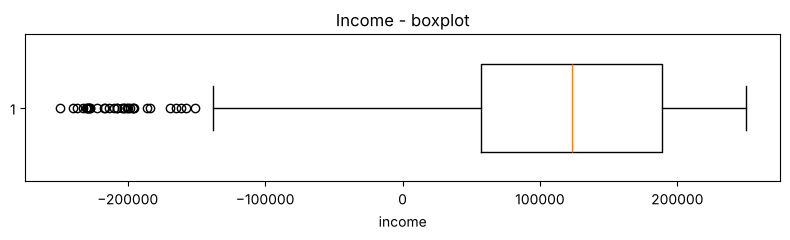

In [ ]:
plt.figure(figsize=(8, 2.5))
plt.boxplot(income, vert=False, widths=0.6)
plt.title("Income - boxplot")
plt.xlabel("income")
plt.tight_layout(); plt.show()

The dots far to the left are the outliers the boxplot flags, and they are all on the
impossible (negative) side.

## A3. The IQR rule, computed

Same rule, now in numbers so you see exactly which points are flagged.

- `quantile(.25)` and `quantile(.75)` give Q1 and Q3.
- IQR = Q3 - Q1 (the middle 50%).
- Anything below Q1 - 1.5*IQR or above Q3 + 1.5*IQR is an outlier.

In [4]:
Q1, Q3 = income.quantile(0.25), income.quantile(0.75)
IQR = Q3 - Q1
low_fence, high_fence = Q1 - 1.5*IQR, Q3 + 1.5*IQR
iqr_outliers = income[(income < low_fence) | (income > high_fence)]

print(f"Q1={Q1:.0f}  Q3={Q3:.0f}  IQR={IQR:.0f}")
print(f"fences: [{low_fence:.0f}, {high_fence:.0f}]")
print(f"IQR flagged {len(iqr_outliers)} outliers; all negative? {(iqr_outliers < 0).all()}")
print("a few:", sorted(iqr_outliers.round(0).tolist())[:5])

Q1=57266  Q3=188598  IQR=131332
fences: [-139732, 385596]
IQR flagged 34 outliers; all negative? True
a few: [-249518.0, -239986.0, -237050.0, -232690.0, -230391.0]


## A4. The z-score method

The z-score says how many standard deviations a value is from the mean: z = (value - mean) / std.
The common rule flags any point with absolute z above 3.

In [5]:
mean, std = income.mean(), income.std()
z = (income - mean) / std
z_outliers = income[z.abs() > 3]

print(f"mean={mean:.0f}  std={std:.0f}")
print(f"z-score (|z|>3) flagged {len(z_outliers)} outliers")
print(f"IQR flagged {len(iqr_outliers)} outliers")

mean=109385  std=103412
z-score (|z|>3) flagged 21 outliers
IQR flagged 34 outliers


**Compare the two, and notice the IQR rule flags more.** Both catch the impossible negatives,
but the z-score catches fewer. Here is why, and it is the important lesson: those extreme negative
values drag the **mean** down and inflate the **standard deviation**, so the z-score's own yardstick
is contaminated by the very outliers it is trying to measure. The IQR rule is built on the median
and quartiles, which the outliers barely move, so it is more **robust**. When in doubt, trust the
boxplot/IQR.

## A5. The judgment call

The methods flagged these points. Now a human decides what they are.

Here, every flagged income is **negative**, which is impossible, so these are clearly **data-entry
errors**, not real people. The right action is to fix or remove them, which is exactly the data
cleaning you did in the preprocessing module. Outlier detection and data cleaning are the same
skill viewed from two sides.

The contrast to keep in mind: if the flagged value had been a genuine high earner, say 240,000,
that would be a **real extreme**, unusual but valid, and you would keep it. The method only raises
the flag; you decide error versus real.

---
# Part B (Optional): when one column is not enough

## B1. The problem

The methods in Part A look at one column at a time. But a point can be perfectly normal on every
column and still be an outlier because of the **combination** of its values.

Classic example: height and weight are related, taller people tend to weigh more. Someone of
average height who is extremely light is unusual, even though an average height is normal and that
weight, on its own, is within the normal range. We build exactly that.

In [53]:
rng = np.random.default_rng(7)
n = 100
height = rng.normal(170, 7, n)                       # cm
weight = 0.9*(height - 170) + 65 + rng.normal(0, 2.0, n)   # taller -> heavier (correlated)

# one combination outlier: average height, but far too light for that height
combo = np.array([[171, 47]])
data = np.vstack([np.column_stack([height, weight]), combo])
print("data shape:", data.shape, " (last row is our planted combination outlier)") 

data shape: (101, 2)  (last row is our planted combination outlier)


## B2. Single-column methods miss it

Run the z-score on each column by itself and check our planted point (the last row).

In [7]:
z_height = (data[:, 0] - data[:, 0].mean()) / data[:, 0].std()
z_weight = (data[:, 1] - data[:, 1].mean()) / data[:, 1].std()

print(f"Our point -> height z = {z_height[-1]:.2f},  weight z = {z_weight[-1]:.2f}")
print(f"Flagged by height alone (|z|>3)? {abs(z_height[-1]) > 3}")
print(f"Flagged by weight alone (|z|>3)? {abs(z_weight[-1]) > 3}")

Our point -> height z = 0.36,  weight z = -2.76
Flagged by height alone (|z|>3)? False
Flagged by weight alone (|z|>3)? False


Neither column flags it: on height it is dead average, and its weight, while low, is still
within the normal spread. A column-at-a-time method is blind to it. You can see why in the scatter:
the point sits well off the height-weight trend line.

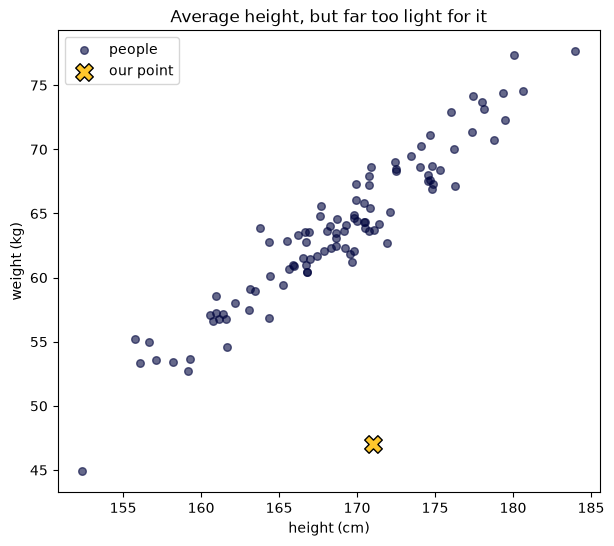

In [59]:
plt.figure(figsize=(7, 6))
plt.scatter(data[:-1, 0], data[:-1, 1], color=ETSU_NAVY, s=30, alpha=0.6, label="people")
plt.scatter(data[-1, 0], data[-1, 1], color=ETSU_GOLD, s=160, marker="X", edgecolors="black", label="our point")
plt.xlabel("height (cm)")
plt.ylabel("weight (kg)")
plt.title("Average height, but far too light for it")
plt.legend()
plt.show()

## B3. A distance-based method catches it

Idea: an outlier is a point whose nearest neighbors are far away. For each point we measure the
average distance to its k nearest neighbors, giving every point a single "how lonely am I" score.
Then we flag the points whose score is unusually high.

**Scale first.** Height (around 170) and weight (around 65) are on different scales, and distance
would be dominated by height otherwise. `StandardScaler` puts both on equal footing, same reason as
in clustering and PCA.

In [62]:
# scale so neither feature dominates the distance
Xs = StandardScaler().fit_transform(data)

# average distance to each point's 5 nearest neighbors = its outlier score
k = 5
distances, _ = NearestNeighbors(n_neighbors=k).fit(Xs).kneighbors(Xs)
scores = distances.mean(axis=1)

# flag points whose score is unusually high
threshold = scores.mean() + 2.5 * scores.std()
is_outlier = scores > threshold
print(is_outlier)
print(f"Flagged {is_outlier.sum()} outlier(s).")
print(f"Our planted point flagged? {is_outlier[-1]}  (its score {scores[-1]:.2f} vs threshold {threshold:.2f})")

[False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False  True False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False  True]
Flagged 2 outlier(s).
Our planted point flagged? True  (its score 1.66 vs threshold 0.70)


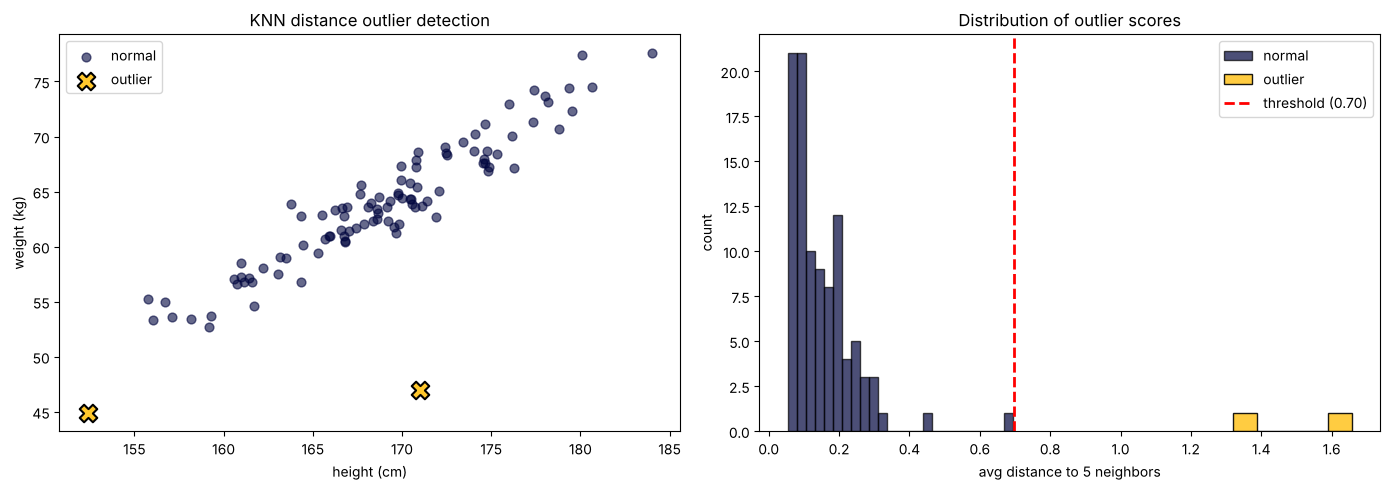

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# left: the data, colored by outlier status
ax[0].scatter(data[~is_outlier, 0], data[~is_outlier, 1], color=ETSU_NAVY, s=40, alpha=0.6, label="normal")
ax[0].scatter(data[is_outlier, 0], data[is_outlier, 1], color=ETSU_GOLD, s=160, marker="X",
              edgecolors="black", linewidths=1.5, label="outlier")
ax[0].set_xlabel("height (cm)"); ax[0].set_ylabel("weight (kg)")
ax[0].set_title("KNN distance outlier detection"); ax[0].legend()

# right: the distribution of the distance scores, with the threshold
ax[1].hist(scores[~is_outlier], bins=25, color=ETSU_NAVY, alpha=0.7, edgecolor="black", label="normal")
ax[1].hist(scores[is_outlier], bins=5, color=ETSU_GOLD, alpha=0.9, edgecolor="black", label="outlier")
ax[1].axvline(threshold, color="red", linestyle="--", linewidth=2, label=f"threshold ({threshold:.2f})")
ax[1].set_xlabel("avg distance to 5 neighbors"); ax[1].set_ylabel("count")
ax[1].set_title("Distribution of outlier scores"); ax[1].legend()

plt.tight_layout(); plt.show()

## B4. The idea underneath, and what you would use in practice

Look at what we just did: we took two columns, collapsed them into **one** distance score per point,
and then flagged the high scores with a z-score-style rule (mean + 2.5 standard deviations). That is
exactly the **multivariate-to-univariate** idea from the lecture: turn many columns into a single
"distance from normal" number, then threshold that one number.

We hand-rolled the distance method so you can see the mechanism. In practice you would reach for a
ready-made detector that does this more cleverly, such as `LocalOutlierFactor` or `IsolationForest`
in scikit-learn. Same idea, one line of code.

---
## Wrap-up: which method, when

- **One numeric column:** use the **boxplot / IQR** rule (robust, and you can see it) or the **z-score**. Reach for IQR first; it is not fooled by the very outliers it is measuring.
- **Several columns, where points can be odd in combination:** use a **distance-based** method (or clustering-based), which looks at all the columns together.
- **Always the last step:** the method flags a point, a **human decides** whether it is an error to fix or a real extreme to keep. That judgment is the real skill.